# M2 — Traditional machine learning for beach-bird detection

**A guided explanation, executable implementation, and report experiment.**

This notebook accompanies `M2_report.md` and `detector.py`. It builds a detector from
handcrafted features and labelled crops; no pretrained bird model is used.

| Variant | Representation | Classifier | Training change |
|---|---|---|---|
| M2-A | HOG | Linear SVM | Initial positive/background samples |
| M2-B | HOG + HSV histograms | Linear SVM | Exactly the same initial samples |
| M2-C | Better validated feature set | Linear SVM | One round of hard-negative mining |

**Dataset status:** the Beach Bird dataset is now available and its local path is configured.
The measured full experiment is presented separately in `M2_full_results.ipynb`
and `M2_report.md`. This walkthrough retains its teaching code and explanatory
diagrams; diagrams and synthetic checks are not bird performance results.
The full experiment runner reuses identical window features across classifiers
and uses local worker processes to reduce repeated work. See `run_full.py`.

For the report, merge the literature, method, setup, results, discussion and conclusion
contributions from `M2_report.md` into your group's corresponding sections.

## 1. How to run

This workspace has a prepared Python 3.12 `.venv`. Launch Jupyter with
`.venv/bin/python -m jupyterlab m2_ml/M2_full_results.ipynb` to inspect the measured results.
The setup steps below apply to a fresh checkout with Python 3.10 or newer.

From the repository root, using Python **3.10 or newer**:

```bash
python3 -m venv .venv
source .venv/bin/activate                 # Windows: .venv\Scripts\activate
python -m pip install -r requirements-m2.txt
python -m jupyterlab m2_ml/M2_walkthrough.ipynb
```

Choose that environment as the notebook kernel. This M2-specific requirements file
avoids deep-learning packages. If your existing project environment already has
the packages, install just the missing ones there.

Place the dataset at the default path below, or set `DATA_ROOT` in Section 2:

```text
data/raw/Beach Bird Detection Dataset v1.0/
  images/train/*.jpg    labels/train/*.txt
  images/val/*.jpg      labels/val/*.txt
  images/test/*.jpg     labels/test/*.txt
```

Labels must exist for every image. An empty label file means no birds. The shared
`configs/paths.yaml` is used if present; an explicit `DATA_ROOT` takes precedence.

1. Run the notebook once with `RUN_EXPERIMENTS=False` to read the explanation.
2. Add the dataset, enable experiments, and use `PROFILE='quick'` to verify your setup.
3. Use `PROFILE='full'` for final training and validation. Restart and run all cells.
4. Read the measured runtime estimate before launching all validation scans.
5. Inspect the validation comparisons, freeze the final variant, then enable the
   separate final-test cell once. Do not make further choices using test results.

The test cell has an explicit switch to avoid accidentally using test results while
learning or tuning. Notebook reruns with a new run directory are separate experiments.

In [1]:
from dataclasses import asdict, replace
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter
import copy
import json
import os
import sys
import warnings

# Find the repository whether Jupyter starts in the repo, m2_ml, or its parent.
roots = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for base in roots for p in (base, base / "Comp9517-bird-detection")
             if (p / "m2_ml" / "detector.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the project folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import display
from skimage.color import rgb2gray, rgb2hsv
from skimage.feature import hog
from sklearn.exceptions import ConvergenceWarning

from m2_ml.detector import (
    Config, crop_rgb, environment_info, evaluate_predictions, extract_features,
    fit_model, iou_one_to_many, iter_windows, learn_templates, load_records,
    make_training_features, mine_hard_negatives, predict_records,
    predictions_from_raw, proposal_recall, read_rgb, save_bundle, scan_records,
    subset, nms,
)

# Convergence failures should stop an experiment instead of silently being ignored.
warnings.filterwarnings("error", category=ConvergenceWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print("Repository:", ROOT)
print("Python:", sys.version.split()[0])

Repository: /Users/apple/Desktop/COMP9517 group project/Comp9517-bird-detection
Python: 3.12.14


/Users/apple/Desktop/COMP9517 group project/Comp9517-bird-detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Settings and split discipline

The classifier sees **training crops only**. The validation split selects `C`,
score floor, NMS threshold and final variant. Test images are not loaded until the
last section is enabled. Crops from an image never move into another split.

The quick profile uses up to 80 training images, 12 validation images and 12 mining
images. Its six templates and larger stride reduce search cost. It is a debugging
experiment, not a final result. The full profile uses all training/validation
images, nine templates, and a quarter-window stride. Training positives are capped
at 12,000 and mining at 6,000 additional negatives from a fixed 160-image training subset; the manifest records actual use.

Optional environment variables (`M2_RUN_EXPERIMENTS`, `M2_PROFILE`, `M2_DATA_ROOT`,
`M2_OUTPUT_ROOT`, `M2_RUN_ID`) support reproducible automated checking. Normal users
can simply edit the variables in this cell.

In [2]:
RUN_EXPERIMENTS = os.environ.get("M2_RUN_EXPERIMENTS", "0") == "1"  # edit to True
PROFILE = os.environ.get("M2_PROFILE", "quick")                     # or "full"
if PROFILE not in {"quick", "full"}:
    raise ValueError("PROFILE must be quick or full")

DATA_ROOT = ROOT / "data/raw/Beach Bird Detection Dataset v1.0"
if (ROOT / "configs/paths.yaml").is_file():
    from utils.data import get_data_root
    DATA_ROOT = get_data_root()
DATA_ROOT = Path(os.environ.get("M2_DATA_ROOT", str(DATA_ROOT))).expanduser().resolve()

RUN_ID = os.environ.get("M2_RUN_ID", datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ"))
OUTPUT_ROOT = Path(os.environ.get("M2_OUTPUT_ROOT", str(ROOT / "results/m2")))
RUN_DIR = OUTPUT_ROOT / PROFILE / RUN_ID

cfg = Config()
if PROFILE == "quick":
    cfg = replace(cfg, n_templates=6, stride_fraction=0.40,
                  max_positives=2000, negatives_per_image=12, max_hard_negatives=256)
TRAIN_LIMIT = 80 if PROFILE == "quick" else None
VAL_LIMIT = 12 if PROFILE == "quick" else None
MINING_IMAGE_LIMIT = 12 if PROFILE == "quick" else 160
C_GRID = (0.1, 1.0)
NMS_GRID = (0.3, 0.5)
SCORE_FLOORS = (-2.0, -1.0)
# Diagnostic limits do not change the actual training/validation split sizes.
PROPOSAL_DIAGNOSTIC_IMAGES = 5 if PROFILE == "quick" else None

# This changes overlays only, not AP evaluation.
VISUAL_SCORE_FLOOR = 0.0
print("Dataset:", DATA_ROOT)
print("Experiments enabled:", RUN_EXPERIMENTS, "| profile:", PROFILE)
print("Output directory:", RUN_DIR)
print("Default features: 1764 HOG dimensions; 1788 with HSV")

Dataset: /Users/apple/Desktop/COMP9517 group project/Comp9517-bird-detection/Beach Bird Detection Dataset v1.0
Experiments enabled: False | profile: quick
Output directory: /Users/apple/Desktop/COMP9517 group project/Comp9517-bird-detection/results/m2/quick/20261114T104947_047315Z
Default features: 1764 HOG dimensions; 1788 with HSV


## 3. The whole detector in plain language

Imagine moving a small rectangle over a beach image. At each position, ask:
**does the content inside this rectangle look like a bird?** Repeat with rectangles
of different sizes and aspect ratios.

1. **Crop and resize:** turn every rectangle into a fixed-size 32 × 32 patch.
2. **HOG:** describe the directions and strengths of edges within the patch.
3. **Optional colour:** describe how much hue, saturation and brightness fall in
   each histogram bin.
4. **SVM:** combine those numbers into one bird-versus-background score.
5. **NMS:** when several boxes surround the same bird, keep the strongest one.

A classifier predicts a score for one patch. A detector additionally decides which
patches to examine and turns scores into image coordinates. Therefore high crop
classification accuracy alone would not establish good detection performance.

```text
Training images + boxes ─→ positive/background crops ─→ features ─→ scaler + SVM
          └──────────────→ training box sizes ─→ window templates

New image ─→ multiscale windows ─→ same features ─→ SVM scores ─→ NMS ─→ bird boxes

Training false alarms ─→ extra background crops ─→ refit scaler + SVM (M2-C)
```

## 4. Why HOG works, and what the features mean

HOG is a **histogram of oriented gradients**. It measures local intensity changes:

\[
G_x=\partial I/\partial x,\quad G_y=\partial I/\partial y,\quad
m=\sqrt{G_x^2+G_y^2},\quad\theta=\operatorname{atan2}(G_y,G_x)\pmod{180^\circ}.
\]

Each pixel votes for an orientation bin, weighted by edge strength. Neighbouring
cells are grouped and normalised so that local contrast changes have less effect.
The implementation reuses scikit-image's compiled cell-histogram kernel and vectorises overlapping block normalisation; the public descriptor remains a reference backend.

For our 32 × 32 crop: 4 × 4 cells give 8 × 8 cells; 2 × 2-cell blocks give 7 × 7
positions. Each block holds 2 × 2 × 9 numbers, so HOG has **1,764 dimensions**.

M2-B adds **24 colour features**: eight-bin H, S and V histograms, each summing to one.
Colour could help with beach backgrounds; it could also cause background or lighting
bias. That is why we test it rather than assume it improves performance.

The next illustration is a hand-drawn schematic, **not a dataset bird**.

For the full run, block normalisation is vectorised around scikit-image's compiled cell-histogram kernel. Tests check agreement with the public `hog` descriptor at 1e-12 tolerance. Crop boundaries, bins, epsilon, clipping and flattening order are preserved.

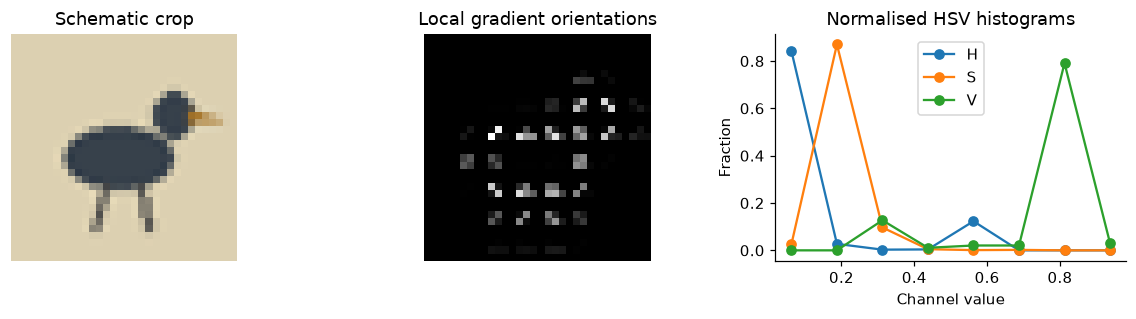

HOG dimensions: 1764
HOG + HSV dimensions: 1788


In [3]:
schematic = Image.new("RGB", (64, 64), (220, 208, 177))
draw = ImageDraw.Draw(schematic)
draw.ellipse((15, 26, 45, 43), fill=(55, 65, 75))
draw.ellipse((40, 16, 51, 29), fill=(55, 65, 75))
draw.polygon([(50, 21), (59, 24), (50, 25)], fill=(165, 115, 40))
draw.line((26, 42, 23, 55), fill=(65, 65, 65), width=2)
draw.line((36, 42, 38, 55), fill=(65, 65, 65), width=2)
patch = np.asarray(schematic.resize((cfg.patch_size, cfg.patch_size)))
descriptor, hog_picture = hog(
    rgb2gray(patch), orientations=cfg.orientations,
    pixels_per_cell=(cfg.cell_size, cfg.cell_size),
    cells_per_block=(cfg.block_cells, cfg.block_cells),
    block_norm="L2-Hys", visualize=True)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].imshow(patch); axes[0].set_title("Schematic crop"); axes[0].axis("off")
axes[1].imshow(hog_picture, cmap="gray"); axes[1].set_title("Local gradient orientations")
axes[1].axis("off")
for channel, label in enumerate(["H", "S", "V"]):
    hist, edges = np.histogram(rgb2hsv(patch)[..., channel], bins=cfg.hsv_bins, range=(0, 1))
    axes[2].plot((edges[:-1]+edges[1:])/2, hist/hist.sum(), marker="o", label=label)
axes[2].set(title="Normalised HSV histograms", xlabel="Channel value", ylabel="Fraction")
axes[2].legend(); fig.tight_layout(); plt.show()
print("HOG dimensions:", len(descriptor))
print("HOG + HSV dimensions:", len(extract_features(patch, cfg, True)))

## 5. What the SVM learns

The feature vector is standardised with training means and standard deviations.
The SVM learns weights $\mathbf w$ and an intercept $b$:

\[
s(\mathbf x)=\mathbf w^\top\mathbf z(\mathbf x)+b.
\]

A positive score supports the bird class; a negative score supports background.
The magnitude ranks detections. A score of 2 does **not** mean 200% confidence, and
negative-scoring windows can still be useful for computing the full precision–recall
curve. The score floor therefore needs validation.

`LinearSVC` uses L2 regularisation and squared-hinge loss by default. Smaller `C`
puts more emphasis on keeping the weights small; larger `C` penalises training
errors more strongly. We compare 0.1 and 1.0 using **image-level validation AP50**.
Class weights compensate for the unequal numbers of positive and background crops.
The scaler is refitted only when a training set changes, never on validation/test.

## 6. Why NMS is needed

One bird can produce many overlapping positive windows. Greedy non-maximum
suppression keeps the highest-scoring box and removes lower-scoring boxes whose
IoU with it exceeds a threshold:

\[
\mathrm{IoU}(A,B)=\frac{|A\cap B|}{|A\cup B|}.
\]

Low NMS thresholds remove more boxes. In dense flocks they can also remove a
neighbouring bird, so we compare 0.3 and 0.5 on validation. The illustration below
has arbitrary scores and boxes; it is not a detector output on real birds.

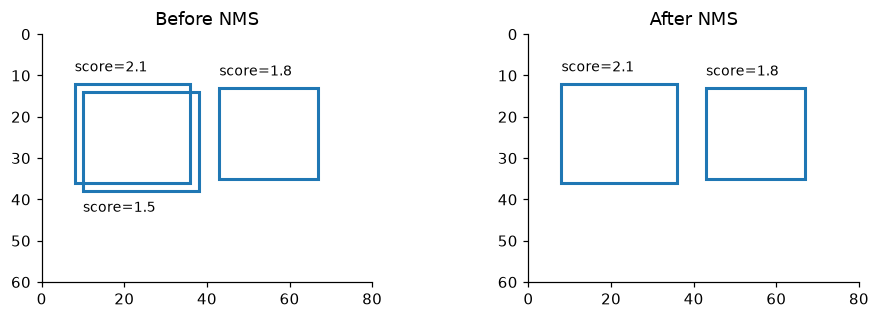

In [4]:
example_boxes = np.array([[8, 12, 28, 24], [10, 14, 28, 24], [43, 13, 24, 22]])
example_scores = np.array([2.1, 1.5, 1.8])
kept = nms(example_boxes, example_scores, iou_threshold=0.3)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, indices, title in zip(axes, [range(3), kept], ["Before NMS", "After NMS"]):
    ax.set(xlim=(0, 80), ylim=(60, 0), title=title, aspect="equal")
    for i in indices:
        x,y,w,h = example_boxes[i]
        ax.add_patch(Rectangle((x,y),w,h, fill=False, edgecolor="tab:blue", linewidth=2))
        label_y = y+h+5 if i==1 else y-3
        ax.text(x,label_y,f"score={example_scores[i]:.1f}",fontsize=9)
fig.tight_layout(); plt.show()

## 7. Load training and validation images

YOLO labels contain `class, centre_x, centre_y, width, height`, normalised by image
size. The shared loader converts them into pixel `[x, y, width, height]` boxes.
Our M2 wrapper additionally rejects missing or malformed labels.

An empty labelled image is important: false alarms on it must affect evaluation.
Missing labels are not silently treated as negative scenes.

In [5]:
train_records, val_records = [], []
if RUN_EXPERIMENTS:
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    train_all = load_records(DATA_ROOT, "train")
    val_all = load_records(DATA_ROOT, "val")
    train_records = subset(train_all, TRAIN_LIMIT, cfg.seed)
    val_records = subset(val_all, VAL_LIMIT, cfg.seed)
    train_names = {r.path.stem for r in train_all}
    val_names = {r.path.stem for r in val_all}
    if train_names & val_names:
        raise ValueError("Repeated image IDs across train/val; investigate split leakage.")
    if not any(len(r.boxes) for r in val_records):
        raise ValueError("Selected validation images contain no birds; use a larger subset.")
    rows = []
    for name, records in [("train", train_records), ("val", val_records)]:
        rows.append({"split": name, "images": len(records),
                     "bird_boxes": sum(len(r.boxes) for r in records),
                     "negative_images": sum(len(r.boxes)==0 for r in records)})
    display(pd.DataFrame(rows))
else:
    print("Dataset cells skipped. Add the dataset and enable RUN_EXPERIMENTS in Section 2.")

Dataset cells skipped. Add the dataset and enable RUN_EXPERIMENTS in Section 2.


## 8. Inspect training geometry and representative windows

Window sizes should come from the **training annotations**, rather than guessing
that all birds are the same size. We cluster log(width, height), so changes in scale
are treated proportionally. K-means centres yield representative sizes and aspect
ratios. This is window geometry, not bird/background classification.

Use the plots to check whether tiny birds or unusual aspect ratios need additional
templates. Such changes must be selected using training/validation only.

In [6]:
shared_preparation_seconds = None
if RUN_EXPERIMENTS:
    preparation_start = perf_counter()
    template_start = perf_counter()
    templates = learn_templates(train_records, cfg)
    template_seconds = perf_counter() - template_start
    sizes = np.concatenate([r.boxes[:,2:] for r in train_records if len(r.boxes)])
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].hist(np.sqrt(np.prod(sizes, axis=1)), bins=30)
    axes[0].set(xlabel="Square root of bird box area (pixels)", ylabel="Count",
                title="Training object sizes")
    axes[1].scatter(sizes[:,0], sizes[:,1], s=5, alpha=.25, label="Training boxes")
    t=np.asarray(templates)
    axes[1].scatter(t[:,0],t[:,1], marker="x",s=90,color="tab:red",label="Templates")
    axes[1].set(xlabel="Width (pixels)",ylabel="Height (pixels)",xscale="log",yscale="log")
    axes[1].legend(); fig.tight_layout()
    fig.savefig(RUN_DIR / "training_box_geometry.png", bbox_inches="tight"); plt.show()
    print("Templates (width, height):", templates)
    print("Windows on first validation image:", sum(1 for _ in iter_windows(
        val_records[0].width, val_records[0].height, templates, cfg)))

## 9. Build paired training features

Bird boxes produce positive crops. Background windows are accepted only when
**both** conditions hold against every bird box:

- IoU < 0.10;
- intersection / bird area < 0.10.

The second test matters: a very large window can contain an entire tiny bird while
still having a low IoU. Labelling that window as background would give the classifier
contradictory supervision. Dense images may yield fewer background examples because
sampling attempts are bounded.

M2-A and M2-B use exactly the same crops and labels. Both feature sets are generated
together, so their initial feature-extraction cost is recorded as shared preparation.
This paired design controls the comparison but slightly overcharges baseline HOG
training time, since it also computes HSV during preparation. Caps, seeds, image IDs
and crop counts are saved for reproducibility.

In [7]:
if RUN_EXPERIMENTS:
    feature_start = perf_counter()
    X_by_feature, y_train, crop_audit = make_training_features(train_records, templates, cfg)
    feature_seconds = perf_counter() - feature_start
    shared_preparation_seconds = template_seconds + feature_seconds
    pd.DataFrame(crop_audit).to_csv(RUN_DIR / "training_crop_counts.csv", index=False)
    print("Shapes:", {name: X.shape for name,X in X_by_feature.items()})
    print("Positive crops:", int((y_train==1).sum()), "| background crops:", int((y_train==0).sum()))
    print("Shared preparation seconds:", round(shared_preparation_seconds, 3))

## 10. Detection metric sanity check and candidate recall

Our primary metric is **mAP@0.5**. There is one class, so it equals bird AP50.
A correct detection must overlap an unmatched annotated bird by IoU ≥ 0.5; extra
boxes and detections on negative images are false positives. The shared COCO
evaluator sweeps score rankings to compute precision–recall and AP. It is not crop
classification accuracy.

Before using learned predictions, ground-truth boxes scored as predictions should
give AP50 ≈ 1. This checks box coordinates and image IDs, not model quality.

**Candidate recall** asks whether the window search places any box with IoU ≥ 0.5
around each bird. A classifier cannot rescue a bird when no sufficiently aligned
candidate is searched. The diagnostic uses a labelled validation subset and is
reported separately from AP. Small/medium/large AP50 categories follow COCO box-area
thresholds (<32², 32²–96², >96²); an empty category is N/A.

In [8]:
proposal_diagnostic = None
if RUN_EXPERIMENTS:
    perfect = [{"image_id": r.path.stem, "bbox": b.tolist(), "score": 1.0}
               for r in val_records for b in r.boxes]
    perfect_metrics = evaluate_predictions(perfect, val_records, RUN_DIR / "eval", "perfect_check")
    assert np.isclose(perfect_metrics["AP50"], 1.0), perfect_metrics
    diagnostic_records = subset(val_records, PROPOSAL_DIAGNOSTIC_IMAGES, cfg.seed)
    proposal_diagnostic = proposal_recall(diagnostic_records, templates, cfg)
    proposal_diagnostic["images"] = [r.path.name for r in diagnostic_records]
    print("Perfect-box AP50:", perfect_metrics["AP50"])
    print("Candidate recall diagnostic:", proposal_diagnostic)

## 11. Fit one small model and estimate the search cost

Exact per-crop HOG is easy to audit and matches training feature extraction.
It repeats computation in overlapping windows, so small templates and small strides
can be slow. The next cell measures one validation image and estimates the search
cost for all four initial feature/C combinations plus one mined model. It excludes
mining, repeats for final timing and size variation between images; treat it as a
rough estimate. It is not a measured full-run inference result.

If it is too expensive, debug with the quick profile. For a final resource-limited
experiment, predeclare a smaller image subset or a coarser search, rerun all variants
under the same settings, and report the change. Do not silently truncate scans.

In [9]:
pilot_bundle = None
if RUN_EXPERIMENTS:
    pilot_bundle = fit_model(X_by_feature["hog"], y_train, templates,
                             replace(cfg,C=C_GRID[0]), use_color=False)
    pilot_predictions, pilot_times = predict_records(val_records[:1], pilot_bundle)
    seconds = pilot_times[0]
    model_count = 2 * len(C_GRID) + 1
    print(f"First validation image: {seconds:.3f} seconds (includes NMS)")
    print(f"Rough {model_count}-model validation-scan estimate: "
          f"{seconds*len(val_records)*model_count/60:.1f} minutes; mining and retiming extra.")
    print("Images differ in size and window count; this is an estimate, not a benchmark.")

## 12. Train M2-A / M2-B and select parameters on validation

For each feature representation and `C`, fit on training crops. Cache up to 5,000
highest-scoring windows per validation image at the lowest tested score floor,
then reuse those scores for the NMS/floor grid. This prevents recomputing HOG for
postprocessing-only changes and bounds cache memory.

Each feature variant gets the same `C`, NMS and score-floor search budget. Selection
uses AP50, with the first candidate in the stated grid winning an exact tie.
Validation grid scores are model-selection evidence, not unbiased final-test results.

The scoring floor and pre-NMS cap can limit recall. If scores cluster below the
lowest tested floor or the candidate cap is routinely hit, investigate a broader
validation sweep before freezing the model. The cap remains identical across variants.

In [10]:
# Helpers used by both initial training and the mined model.
def tune_postprocessing(bundle, name):
    start = perf_counter()
    raw, scan_times = scan_records(val_records, bundle, score_floor=min(SCORE_FLOORS))
    candidates = []
    for nms_value in NMS_GRID:
        for floor in SCORE_FLOORS:
            setting = replace(Config(**bundle["config"]), nms_iou=nms_value, score_floor=floor)
            predictions = predictions_from_raw(raw, setting)
            tag = f"{name}_nms{nms_value}_floor{floor}"
            metrics = evaluate_predictions(predictions, val_records, RUN_DIR / "eval", tag)
            candidates.append({"variant": name, "C": setting.C, "nms_iou": nms_value,
                               "score_floor": floor, **metrics})
    winner = max(candidates, key=lambda row: row["AP50"])
    selected = dict(bundle)
    selected["config"] = asdict(replace(Config(**bundle["config"]),
        nms_iou=winner["nms_iou"], score_floor=winner["score_floor"]))
    seconds = perf_counter() - start
    return selected, candidates, seconds

bundles, selected_rows, all_trials = {}, {}, []
search_seconds = 0.0
if RUN_EXPERIMENTS:
    for name, feature_name, use_color in [("M2-A", "hog", False), ("M2-B", "hog_color", True)]:
        choices = []
        for C in C_GRID:
            fitted = fit_model(X_by_feature[feature_name], y_train, templates,
                               replace(cfg,C=C), use_color=use_color)
            selected, rows, elapsed = tune_postprocessing(fitted, name)
            search_seconds += fitted["fit_seconds"] + elapsed
            all_trials.extend(rows)
            best_row = max(rows, key=lambda row: row["AP50"])
            choices.append((selected, best_row))
        bundle, row = max(choices, key=lambda pair: pair[1]["AP50"])
        bundle["feature_name"] = feature_name
        bundle["variant"] = name
        bundle["training_pipeline_seconds"] = shared_preparation_seconds + bundle["fit_seconds"]
        bundle["shared_preparation_seconds"] = shared_preparation_seconds
        bundles[name], selected_rows[name] = bundle, dict(row)
    pd.DataFrame(all_trials).to_csv(RUN_DIR / "validation_search.csv", index=False)
    display(pd.DataFrame(selected_rows.values()))

## 13. Hard-negative mining — M2-C

Random background crops may be easy: plain sand is obviously not a bird. A trained
detector might still confuse a rock, wave edge or shadow with one. Hard-negative
mining deliberately adds the false alarms that the current model finds difficult.

1. Pick the better validated initial feature model.
2. Scan **training images only**; take windows with SVM score ≥ 0.
3. Require the same background IoU and bird-coverage checks as initial sampling.
4. Use NMS at 0.3 to avoid many duplicates, capped at 12/image and 6,000 overall
   (256 overall in quick mode).
5. Retain all original samples, add these negatives, and refit scaler + SVM.

The source `C` stays fixed. We measure M2-C with the source postprocessing unchanged
as a controlled comparison, then give it the same NMS/floor sweep. An improvement
is a hypothesis; if no hard negatives exist, do not claim a new experiment.

In [11]:
mining_audit, matched_mining_metrics = [], None
mining_seconds = 0.0
source_name = None
if RUN_EXPERIMENTS:
    source_name = max(selected_rows, key=lambda name: selected_rows[name]["AP50"])
    source_bundle = bundles[source_name]
    mining_records = subset(train_records, MINING_IMAGE_LIMIT, cfg.seed)
    start = perf_counter()
    hard_X, mining_audit = mine_hard_negatives(mining_records, source_bundle)
    mining_seconds = perf_counter()-start
    pd.DataFrame(mining_audit, columns=["image_id","bbox","score"]).to_csv(
        RUN_DIR / "hard_negatives.csv", index=False)
    print("Mining source:", source_name, "| added negatives:", len(hard_X))
    if len(hard_X):
        feature_name = source_bundle["feature_name"]
        new_X = np.vstack([X_by_feature[feature_name], hard_X])
        new_y = np.concatenate([y_train, np.zeros(len(hard_X), dtype=np.int8)])
        fitted = fit_model(new_X, new_y, templates, Config(**source_bundle["config"]),
                           use_color=source_bundle["use_color"])
        # Evaluate the retrained model with IDENTICAL source postprocessing first.
        raw_mined, _ = scan_records(val_records, fitted, score_floor=min(SCORE_FLOORS))
        matched_predictions = predictions_from_raw(raw_mined, Config(**source_bundle["config"]))
        matched_mining_metrics = evaluate_predictions(
            matched_predictions, val_records, RUN_DIR / "eval", "mining_matched_postprocessing")
        print("Source AP50:", selected_rows[source_name]["AP50"],
              "| mined AP50 with source postprocessing:", matched_mining_metrics["AP50"])
        # Reuse the same raw candidates; avoid another full validation scan.
        rows=[]
        for nms_value in NMS_GRID:
            for floor in SCORE_FLOORS:
                setting=replace(Config(**fitted["config"]),nms_iou=nms_value,score_floor=floor)
                metrics=evaluate_predictions(predictions_from_raw(raw_mined,setting),val_records,
                    RUN_DIR/"eval", f"M2-C_nms{nms_value}_floor{floor}")
                rows.append({"variant":"M2-C","C":setting.C,"nms_iou":nms_value,
                             "score_floor":floor,**metrics})
        row=max(rows,key=lambda row:row["AP50"])
        fitted["config"]=asdict(replace(Config(**fitted["config"]),
            nms_iou=row["nms_iou"],score_floor=row["score_floor"]))
        fitted.update({"variant":"M2-C","feature_name":feature_name,"source_variant":source_name,
                       "hard_negative_count":len(hard_X),"mining_seconds":mining_seconds,
                       "shared_preparation_seconds":shared_preparation_seconds,
                       "training_pipeline_seconds":shared_preparation_seconds+
                           source_bundle["fit_seconds"]+mining_seconds+fitted["fit_seconds"]})
        bundles["M2-C"],selected_rows["M2-C"]=fitted,dict(row)
        all_trials.extend(rows)
        del new_X, new_y, raw_mined
    else:
        print("M2-C unavailable: no eligible hard negatives; initial models remain valid.")

## 14. Measure complete detection time and save validation results

The grid-sweep timing is not used as final inference time because it excludes NMS
and benefits from cached scores. We now detect again with each selected model.
Timing includes image loading, resizing/features, scaling, SVM, NMS and prediction
construction; it excludes model loading, progress updates and disk serialisation.

Training pipeline time includes the shared paired preparation plus the selected
fit. M2-C additionally includes the source fit, mining and refit. Validation search
cost is separate. All methods should be timed on the same machine; the manifest
records software/OS details, and you should add CPU model, RAM and thread settings.

In [12]:
validation_summary = pd.DataFrame()
if RUN_EXPERIMENTS:
    validation_rows=[]
    for name,bundle in bundles.items():
        predictions,times=predict_records(val_records,bundle)
        metrics=evaluate_predictions(predictions,val_records,RUN_DIR/"eval",f"{name}_selected_val")
        np.testing.assert_allclose(metrics["AP50"],selected_rows[name]["AP50"],atol=1e-10)
        bundle["validation_metrics"]=metrics
        save_bundle(bundle,RUN_DIR/f"{name}.joblib")
        (RUN_DIR/f"{name}_val.json").write_text(json.dumps(predictions,allow_nan=False))
        pd.DataFrame({"image_id":[r.path.stem for r in val_records],"seconds":times}).to_csv(
            RUN_DIR/f"{name}_inference_times.csv",index=False)
        validation_rows.append({"variant":name,"profile":PROFILE,"split":"val",
            "images":len(val_records),**metrics,
            "C":bundle["config"]["C"],"nms_iou":bundle["config"]["nms_iou"],
            "score_floor":bundle["config"]["score_floor"],
            "training_pipeline_seconds":bundle["training_pipeline_seconds"],
            "svm_fit_seconds":bundle["fit_seconds"],
            "mean_inference_seconds":float(np.mean(times)),
            "median_inference_seconds":float(np.median(times))})
    validation_summary=pd.DataFrame(validation_rows)
    validation_summary.to_csv(RUN_DIR/"validation_summary.csv",index=False)
    pd.DataFrame(all_trials).to_csv(RUN_DIR/"validation_search.csv",index=False)
    display(validation_summary)
    fig,axes=plt.subplots(1,2,figsize=(10,3.5))
    axes[0].bar(validation_summary.variant,validation_summary.AP50,color="tab:blue")
    axes[0].set(ylabel="AP50",ylim=(0,1),title=f"Validation accuracy ({PROFILE})")
    axes[1].bar(validation_summary.variant,validation_summary.mean_inference_seconds,color="tab:orange")
    axes[1].set(ylabel="Seconds per image",title="Complete detection time")
    fig.tight_layout();fig.savefig(RUN_DIR/"validation_comparison.png",bbox_inches="tight");plt.show()

## 15. Visualise successes and failures

Green boxes are annotations. Orange boxes are detections above the stated display
score floor. This display floor is separate from the lower floor used for AP;
otherwise hundreds of low-scoring candidates can obscure the image.

Choose examples by an explicit criterion: a negative image for false alarms, a
crowded image for duplicate/suppression problems, and a typical labelled image.
Do not show only the easiest examples. For the report, identify specific misses,
false positives and localisation errors; explain them using the candidate geometry,
features, scores and NMS rather than guessing from an aggregate AP number.

In [13]:
def draw_overlay(record, predictions, ax, score_floor=0.0):
    ax.imshow(read_rgb(record)); ax.axis("off")
    for box in record.boxes:
        ax.add_patch(Rectangle(box[:2],box[2],box[3],fill=False,edgecolor="lime",linewidth=1.3))
    visible=[p for p in predictions if p["image_id"]==record.path.stem and p["score"]>=score_floor]
    for p in visible:
        b=p["bbox"]
        ax.add_patch(Rectangle(b[:2],b[2],b[3],fill=False,edgecolor="darkorange",linewidth=1))
    ax.set_title(f"{record.path.name}: {len(record.boxes)} GT, {len(visible)} shown")

if RUN_EXPERIMENTS:
    best_name=max(selected_rows,key=lambda name:selected_rows[name]["AP50"])
    best_bundle=bundles[best_name]
    chosen=[]
    negative=next((r for r in val_records if len(r.boxes)==0),None)
    if negative is not None:chosen.append(negative)
    for r in [max(val_records,key=lambda r:len(r.boxes)),*val_records]:
        if r.path not in [item.path for item in chosen]:chosen.append(r)
        if len(chosen)==3:break
    example_predictions,_=predict_records(chosen,best_bundle)
    fig,axes=plt.subplots(1,len(chosen),figsize=(5*len(chosen),5),squeeze=False)
    for ax,r in zip(axes[0],chosen):draw_overlay(r,example_predictions,ax,VISUAL_SCORE_FLOOR)
    fig.suptitle(f"{best_name}: green = ground truth, orange = scores ≥ {VISUAL_SCORE_FLOOR:g}")
    fig.tight_layout();fig.savefig(RUN_DIR/"validation_examples.png",bbox_inches="tight");plt.show()

## 16. Save a reproducibility manifest and freeze the final choice

The manifest ties report numbers to a run, exact image lists, configuration and
software versions. The selected final model comes from **validation AP50 only**.
A tie uses the first variant in the declared order. Do not refit with validation
crops in this workflow: doing so would change the model and require a different
selection protocol.

CSV exports contain individual timing samples and grid values. Full-split prediction
JSON uses the same format as M1/M3. For quick runs, use only the notebook's
subset-aware evaluator; the CLI evaluator against full validation GT would penalise
the images deliberately excluded from the quick subset.

In [14]:
def json_safe(value):
    if isinstance(value,dict):return {str(k):json_safe(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)):return [json_safe(v) for v in value]
    if isinstance(value,(np.integer,)):return int(value)
    if isinstance(value,(float,np.floating)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value,Path):return str(value)
    return value

manifest = None
if RUN_EXPERIMENTS:
    best_name=max(selected_rows,key=lambda name:selected_rows[name]["AP50"])
    best_bundle=bundles[best_name]
    save_bundle(best_bundle,RUN_DIR/"final_model.joblib")
    manifest={"run_id":RUN_ID,"profile":PROFILE,"data_root":str(DATA_ROOT),
        "environment":environment_info(),"base_config":asdict(cfg),
        "train_images":[r.path.name for r in train_records],
        "validation_images":[r.path.name for r in val_records],
        "training_crop_counts":{"positive":int((y_train==1).sum()),"negative":int((y_train==0).sum())},
        "templates":templates,"C_grid":C_GRID,"NMS_grid":NMS_GRID,"score_floors":SCORE_FLOORS,
        "shared_preparation_seconds":shared_preparation_seconds,
        "initial_validation_search_seconds":search_seconds,
        "mining_images":[r.path.name for r in mining_records],
        "mining_source":source_name,"hard_negative_count":len(mining_audit),
        "mining_seconds":mining_seconds,"matched_mining_metrics":matched_mining_metrics,
        "proposal_diagnostic":proposal_diagnostic,
        "selected_variant":best_name,"selected_config":best_bundle["config"],
        "validation_summary":validation_summary.to_dict(orient="records"),
        "test_evaluated":False}
    (RUN_DIR/"manifest.json").write_text(json.dumps(json_safe(manifest),indent=2,allow_nan=False))
    print("Frozen final M2 variant:",best_name)
    print("Saved results:",RUN_DIR)
    print("Test images have not been loaded or evaluated.")

## 17. Final test — enable once after all choices are frozen

Leave this disabled during development. The full-profile final model is evaluated
on the entire original test split. A marker prevents rerunning this section within
the same run directory. This is a workflow guard, not a substitute for scientific
judgment: do not rerun model selection after looking at test results.

The default evaluates the selected final M2 variant. If your group wants test
ablations too, freeze **all** their settings first and evaluate them in one final
batch, without using those scores for further choices.

In [15]:
RUN_FINAL_TEST = False  # change only after final validation-based model selection
if RUN_FINAL_TEST:
    if not RUN_EXPERIMENTS or PROFILE!="full" or manifest is None:
        raise RuntimeError("Finish a full training/validation run before final testing.")
    marker=RUN_DIR/"FINAL_TEST_STARTED.json"
    if marker.exists():
        raise RuntimeError("Final test already started for this run. Inspect saved outputs.")
    marker.write_text(json.dumps({"selected_variant":best_name,"started_utc":
        datetime.now(timezone.utc).isoformat()},indent=2))
    test_records=load_records(DATA_ROOT,"test")
    other_names={r.path.stem for r in train_all+val_all}
    if other_names & {r.path.stem for r in test_records}:
        raise ValueError("Repeated image IDs between test and development splits.")
    test_predictions,test_times=predict_records(test_records,best_bundle)
    test_metrics=evaluate_predictions(test_predictions,test_records,RUN_DIR/"test_eval","final_test")
    prediction_path=RUN_DIR/"m2_final_test.json"
    prediction_path.write_text(json.dumps(test_predictions,allow_nan=False))
    pd.DataFrame({"image_id":[r.path.stem for r in test_records],"seconds":test_times}).to_csv(
        RUN_DIR/"test_inference_times.csv",index=False)
    test_summary={"variant":best_name,"split":"test","images":len(test_records),**test_metrics,
        "training_pipeline_seconds":best_bundle["training_pipeline_seconds"],
        "mean_inference_seconds":float(np.mean(test_times)),
        "median_inference_seconds":float(np.median(test_times))}
    pd.DataFrame([test_summary]).to_csv(RUN_DIR/"test_summary.csv",index=False)
    manifest.update({"test_evaluated":True,"test_images":[r.path.name for r in test_records],
                     "test_summary":test_summary})
    (RUN_DIR/"manifest.json").write_text(json.dumps(json_safe(manifest),indent=2,allow_nan=False))
    display(pd.DataFrame([test_summary]))
    print("Common-format test predictions:",prediction_path)
else:
    print("Final test is disabled.")

Final test is disabled.


## 18. Explain your M2 section in the presentation

**A short explanation you can adapt:**

> Our M2 method learns to distinguish bird crops from background using handcrafted
> features. We describe each candidate region with HOG, which captures local edge
> structure, and test whether adding HSV colour histograms helps. A linear SVM
> produces a bird score. We search multiple window sizes based on training-box
> dimensions, then use NMS to remove duplicate boxes. Finally, we retrain using
> difficult background windows that the initial detector mistakes for birds.
> We select settings on validation data and reserve test images for final evaluation.

Then state **your measured** AP50 and runtime, show a success and failure, and explain
which comparison supports your conclusion. Do not state that colour or mining helped
unless the experiment supports it.

**Useful questions and answers:**

- **Why is this machine learning?** The SVM weights and feature standardisation
  statistics are learned from labelled training crops.
- **Why not call it deep learning?** The feature extractor is handcrafted HOG/HSV;
  no neural feature extractor is trained or used.
- **Why multiple window sizes?** Birds occupy different numbers of pixels and have
  different box aspect ratios. One fixed rectangle would miss many valid shapes.
- **Why can a small bird be missed?** No candidate may align well enough; resizing
  cannot recreate lost detail; features may resemble background; or NMS may suppress it.
- **Why can AP differ from the displayed boxes?** The overlay uses a higher display
  threshold; AP is computed from the selected ranked candidate range.
- **Why not promise high scores?** A transparent, controlled baseline is valuable;
  report conclusions must follow measured results.

## 19. Map the outputs to the report

| Report subsection | Notebook evidence |
|---|---|
| Literature review | HOG + linear SVM reference; feature and classifier documentation |
| Methods | Sections 3–6, 8–9, 12–13; exact `detector.py` implementation |
| Experimental setup | Settings, image lists, crop counts, template dimensions, manifest |
| Results | `validation_summary.csv`, `test_summary.csv`, comparison and example PNGs |
| Discussion | Size AP, candidate recall, matched-postprocessing mining comparison, overlays |
| Conclusion | Actual selected variant and measured test accuracy/time; evidence-backed limitation |

The corresponding prose is written section by section in `M2_report.md`. The current report uses measured full-run outputs; inspect `M2_full_results.ipynb` for the actual tables and examples. A missing-size-category AP is N/A.
Validation results and test results must stay separate. Suggested plots are generated
only from real run outputs, never from illustrative or synthetic values.

**Optional further work after the core experiment:** evaluate blur or brightness
perturbations at fixed severities, while leaving labels unchanged and model/settings
frozen. Compare clean and distorted versions of the same images and report the
precise perturbation. This robustness experiment is not implemented here and should
not be claimed in the report without doing it.

**Computational limitation:** exact per-crop HOG repeats computation. A shared dense
HOG map could improve efficiency, but boundary gradients and normalisation must match
training; it is not automatically an equivalent drop-in implementation.

## 20. References and implementation attribution

1. N. Dalal and B. Triggs, **Histograms of Oriented Gradients for Human Detection**,
   CVPR 2005, pp. 886–893. [Paper](https://lear.inrialpes.fr/people/triggs/pubs/Dalal-cvpr05.pdf).
   The original application was pedestrians; effectiveness on birds must be measured.
2. scikit-image, [`hog` documentation](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.hog).
3. scikit-learn, [`LinearSVC` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html).
4. scikit-learn, [`StandardScaler` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).

The local code provides window generation, paired crop sampling, HSV concatenation,
vectorised block normalisation, NMS, mining and experiment orchestration. The HOG cell-histogram kernel, K-means, standardisation and SVM optimisation use the stated libraries. NumPy, Pillow, PyYAML, joblib, tqdm, pandas,
Matplotlib and the group's pycocotools evaluator support the workflow. Record actual
library versions in the report/README and cite the dataset in the group report.

Course connections: Week 3 Feature Representation Part 2, slides 34–39 (HOG and
sliding-window classification); Week 4 Pattern Recognition Part 2 (SVMs).

**Code check:** `python -m unittest m2_ml.test_detector -v` runs small synthetic
integration checks. These verify code behaviour, not bird detection performance.